# 02 — Data Splitting & Preprocessing
**Goal:** Clean the dataset, split it chronologically into **Train / Validation / Test**, and demonstrate proper scaling (fit on Train only).

Steps:
1. Load merged dataset
2. Drop missing rows & filter daytime only (`IRRADIATION > 0`)
3. Time-based split (Train / Val / Test by date)
4. Scaling example (`StandardScaler` fit on Train only)
5. Save clean splits (`train_clean.csv`, `val_clean.csv`, `test_clean.csv`)


## 1. Load & Clean Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

# Load merged dataset
df = pd.read_csv("../data/processed/solar_panel_dataset.csv")
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"])

# Drop the 4 rows with missing sensor values
df = df.dropna().reset_index(drop=True)

# Keep daytime rows only (nighttime is always 0 irradiance -> 0 power)
df = df[df["IRRADIATION"] > 0].reset_index(drop=True)

# Sort chronologically before splitting
df = df.sort_values("DATE_TIME").reset_index(drop=True)

print("Clean daytime rows:", len(df))
print("Date range:", df["DATE_TIME"].min(), "to", df["DATE_TIME"].max())


Clean daytime rows: 77098
Date range: 2020-05-15 05:45:00 to 2020-06-17 18:45:00


## 2. Time-Based Split (Train / Validation / Test)
We split **by date** (never randomly) so future timestamps never leak into training:
- **Train (~70%):** May 15 – Jun 7
- **Validation (~15%):** Jun 8 – Jun 12
- **Test (~15%):** Jun 13 – Jun 17

In [2]:
train = df[df["DATE_TIME"] < "2020-06-08"].copy()
val   = df[(df["DATE_TIME"] >= "2020-06-08") & (df["DATE_TIME"] < "2020-06-13")].copy()
test  = df[df["DATE_TIME"] >= "2020-06-13"].copy()

print(f"Train: {len(train):,} rows ({100*len(train)/len(df):.1f}%)")
print(f"Val:   {len(val):,} rows ({100*len(val)/len(df):.1f}%)")
print(f"Test:  {len(test):,} rows ({100*len(test)/len(df):.1f}%)")


Train: 53,338 rows (69.2%)
Val:   11,968 rows (15.5%)
Test:  11,792 rows (15.3%)


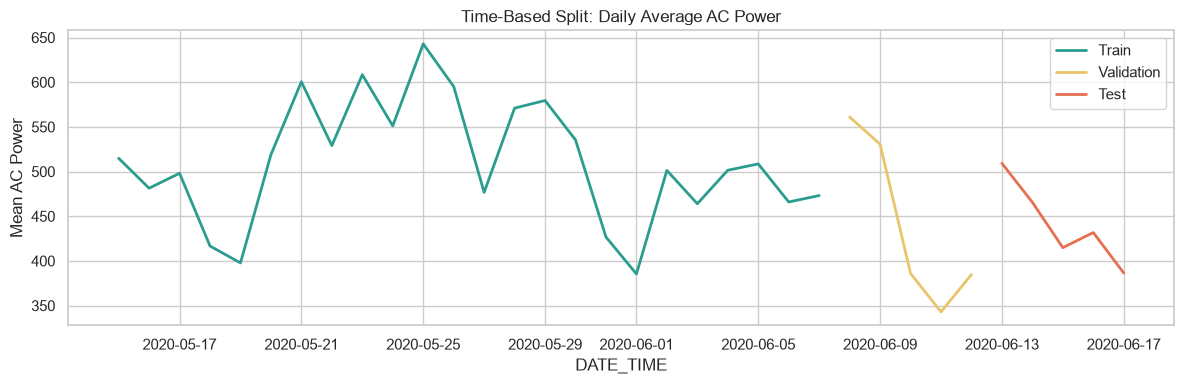

In [3]:
# Visualize the chronological split
daily = df.groupby(df["DATE_TIME"].dt.date)["AC_POWER"].mean()

plt.figure(figsize=(12, 4))
daily[daily.index < pd.to_datetime("2020-06-08").date()].plot(label="Train", color="#2a9d8f", linewidth=2)
daily[(daily.index >= pd.to_datetime("2020-06-08").date()) & (daily.index < pd.to_datetime("2020-06-13").date())].plot(label="Validation", color="#e9c46a", linewidth=2)
daily[daily.index >= pd.to_datetime("2020-06-13").date()].plot(label="Test", color="#e76f51", linewidth=2)
plt.title("Time-Based Split: Daily Average AC Power")
plt.ylabel("Mean AC Power")
plt.legend()
plt.tight_layout()
plt.show()


## 3. Scaling Example (Fit on Train Only!)
`StandardScaler` puts numeric features on the same scale (`mean = 0`, `std = 1`).
Always call `fit_transform` on **Train only**, then `transform` on **Val** and **Test**.

In [4]:
demo_cols = ["IRRADIATION", "MODULE_TEMPERATURE", "AMBIENT_TEMPERATURE", "relative_humidity_2m", "cloud_cover"]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(train[demo_cols])
X_val_scaled   = scaler.transform(val[demo_cols])
X_test_scaled  = scaler.transform(test[demo_cols])

print("Before scaling (IRRADIATION mean, std):", round(train["IRRADIATION"].mean(), 2), round(train["IRRADIATION"].std(), 2))
print("After scaling  (IRRADIATION mean, std):", round(X_train_scaled[:, 0].mean(), 2), round(X_train_scaled[:, 0].std(), 2))


Before scaling (IRRADIATION mean, std): 0.43 0.32
After scaling  (IRRADIATION mean, std): -0.0 1.0


## 4. Save Clean Splits for Feature Engineering

In [5]:
train.to_csv("../data/processed/train_clean.csv", index=False)
val.to_csv("../data/processed/val_clean.csv", index=False)
test.to_csv("../data/processed/test_clean.csv", index=False)

print("Saved clean splits:")
print("  train_clean.csv:", train.shape)
print("  val_clean.csv:  ", val.shape)
print("  test_clean.csv: ", test.shape)


Saved clean splits:
  train_clean.csv: (53338, 29)
  val_clean.csv:   (11968, 29)
  test_clean.csv:  (11792, 29)
